## Exercise: Final EDA Workflow

You are a data scientist working for a financial services company. The company wants to predict which customers are likely to miss payment within the next 60 days. You receive a dataset containing:
- Customer demographics.
- Accounot balances.
- Historical payment records.
- Transaction activity.
- Credit utilization.
- Customer service interactions.
- Account status.
- Payment delinquency outcomes.

Your task is to design a complete exploratory data analysis and preprocessing workflow.

### Project Requirements

Chapter 5 Capstone Checklist
- Problem definition: Define the target, observation unit, prediction timestamp, and success metrics.
- Dataset inspection: Identify features, data types, identifiers, and structural issues.
- Data quality audit: Check missingness, duplicates, invalid values, and inconsistent categories.
- Univariate EDA: Analyze numerical and categorical distributions.
- Multivariate EDA: Investigate correlations, feature relationships, and interactions.
- Target analysis: Evaluate class imbalance and relationships with candidate predictors.
- Leakage audit: Identify unavailable future information and invalid feature construction.
- Evaluation design: Choose a train-validation-test strategy appropriate for 60-day outcomes.
- Preprocessing pipeline: Implement leakage-safe imputation, encoding, and scaling.
- Baseline modeling: Train a baseline model and evaluate appropriate metrics.
- Documentation: Summarize findings, assumptions, limitations, and recommended next steps.

### Expected Deliverables

A complete submission should include a reproducible Jupyter notebook, a documented preprocessing pipeline, appropriate evaluation results, and a written summary of findings.

A strong submission should explain not only what was done, but why each decision was appropriate for the business problem and data structure.

### Stage 1 — Problem Definition

Define the target, observation unit, prediction timestamp, and success metrics. The example dataset has been loaded below.

**Business objective:** Predict which customers are likely to miss at least one scheduled payment within the next 60 days, enabling the financial services company to prioritize preventive outreach.

**Observation unit:** One customer at a monthly snapshot date.

**Prediction timestamp:** The first day of each month, using only information available at that time.

**Target:** A binary variable indicating whether the customer misses at least one scheduled payment during the subsequent 60 days.

**Evaluation:** Use average precision and ROC-AUC to evaluate ranking, precision and recall at operational thresholds, and potentially precision@K for a capacity-constrained outreach program.

**Validation strategy:** Chronological train-validation-test splitting, with safeguards ensuring labels are fully observable at each historical training cutoff.

### Stage 2 — Building and Inspecting Our Dataset

Identify features, data types, identifiers, and structural issues.

#### 2.1 — Dataset Design
We'll simulate 1,000 customers observed monthly for 24 months, producing 24,000 customer-month records. Each row will represent the information available about a customer at a monthly prediction snapshot. Our target will be whether the customer misses at least one scheduled payment in the following 60 days.

| Feature | Description | Type |
| :--- | :--- | :--- |
| `customer_id` | Unique customer identifier | Identifier |
| `snapshot_date` | Monthly prediction timestamp | Datetime |
| `age` | Customer age | Numerical |
| `annual_income` | Estimated annual income | Numerical |
| `account_balance` | Outstanding account balance | Numerical |
| `credit_utilization` | Proportion of available credit used | Numerical |
| `transactions_30d` | Number of transactions in the preceding 30 days | Numerical, discrete |
| `late_payments_12m` | Number of historical late payments | Numerical, discrete |
| `account_tenure_months` | Months since account opening | Numerical, discrete |
| `employment_status` | Employment category | Categorical |
| `region` | Customer region | Categorical |
| `missed_payment_date` | Future missed-payment outcome | Binary target |

We'll also introduce a small number of deliberate data-quality problems in a later stage so you can practice identifying them rather than being told exactly where they are.

**Important modeling distinction**

This dataset will simulate a coherent 60-day outcome process from underlying monthly payment events. That matters because consecutive monthly snapshots have overlapping prediction horizons. For example, a missed payment in March could legitimately produce a positive label for both a February and March snapshot. We should not independently generate unrelated 60-day labels for every monthly row.

#### 2.2 — Creating the Dataset
The generator creates historical missed-payment events and derives each 60-day target from those events. It also uses a fixed random seed so the dataset is reproducible.

Two limitations to remember: this is synthetic data, and the historical features are simulated summaries rather than features reconstructed from a complete transaction ledger. We'll use it to learn the workflow, not to draw real financial conclusions.

#### 2.3 — Set Up Your Notebook
Place the CSV in the same folder as your notebook and load the data into the notebook.

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PATH = './../datasets/financial_customer_months.csv'

def readData(path):    
    dataframe = pd.read_csv(
        path
    )
    return dataframe

df = readData(PATH)

#### 2.4 — Structural Inspection

In Chapter 5.2, we discussed understanding the dataset before making transformations. I want you to write Python code to answer these questions.

**Task A — Basic structure**
1. How many rows and columns are in the dataset?
2. What are the first five observations?
3. What are the data types of each column?
4. How many non-null observations does each column contain?
5. What descriptive statistics can we obtain for numerical and categorical features?

Hints: Think about the Pandas methods shape, head(), dtypes, info(), and describe().

**Task B — Feature classification**

Identify which columns are:
- Numerical continuous.
- Numerical discrete.
- Categorical nominal.
- Identifiers.
- Datetime.
- Target.

A feature being stored as an integer does not necessarily mean it should be treated as a numerical predictor. For example, customer_id is stored numerically, but its magnitude has no meaningful quantitative relationship with payment risk.

**Task C — Understand the observation unit**

Write code to answer:
1. How many unique customers exist?
2. How many unique snapshot dates exist?
3. How many observations exist per customer?
4. What is the earliest snapshot date?
5. What is the latest snapshot date?

Then answer this conceptual question: Why would counting duplicated customer_id values be misleading when determining whether this dataset contains duplicate observations?

**Task D — Identify a potential data type problem**

Inspect the data type of snapshot_date. Pandas often reads dates from CSV files as strings. What would you do to ensure this column is represented as a proper datetime type, and why does that matter for our later temporal splitting?

In [30]:
# Task A - Basic Structure
print('---Basic Structure of the Dataset---')

print('\n---Shape of the dataset:---')
print(df.shape)

print('\n---First 5 rows of data:---')
print(df.head())

print('\n---Datatype of each column:---')
print(df.dtypes)

print('\n---Number of non-null observations in each column:---')
df.info()

print('\n---Descriptive statistics for numerical and categorical features:---')
df.describe(include='all')

---Basic Structure of the Dataset---

---Shape of the dataset:---
(24000, 12)

---First 5 rows of data:---
   customer_id snapshot_date  age  annual_income  account_balance  \
0        10001    2024-01-01   47       42481.25          2231.11   
1        10002    2024-01-01   61       69380.81          5855.66   
2        10003    2024-01-01   34       52645.80          6305.26   
3        10004    2024-01-01   28       44475.26          5096.54   
4        10005    2024-01-01   71       45374.93          2588.58   

   credit_utilization  transactions_30d  late_payments_12m  \
0              0.2342                19                  0   
1              0.4547                14                  0   
2              0.5199                20                  0   
3              0.2667                26                  0   
4              0.2399                19                  0   

   account_tenure_months employment_status     region  missed_payment_60d  
0                     42     

,customer_id,snapshot_date,age,annual_income,account_balance,credit_utilization,transactions_30d,late_payments_12m,account_tenure_months,employment_status,region,missed_payment_60d
count,24000.000000,24000,24000.000000,24000.00000,24000.000000,24000.000000,24000.000000,24000.000000,24000.000000,24000,24000,24000.000000
unique,NaN,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,4,NaN
top,NaN,2024-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Employed,Northeast,NaN
freq,NaN,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16800,6144,NaN
mean,10500.500000,NaN,48.313000,77204.48691,4688.554498,0.397754,18.389042,0.302458,72.598000,NaN,NaN,0.067292
std,288.681005,NaN,16.164341,40283.67506,2421.885488,0.207989,4.842606,0.586934,35.877133,NaN,NaN,0.250532
min,10001.000000,NaN,21.000000,18000.00000,0.000000,0.000000,4.000000,0.000000,1.000000,NaN,NaN,0.000000
25%,10250.750000,NaN,34.000000,48926.50250,2917.317500,0.241400,15.000000,0.000000,42.000000,NaN,NaN,0.000000
50%,10500.500000,NaN,48.500000,68299.47000,4599.345000,0.385600,18.000000,0.000000,73.000000,NaN,NaN,0.000000
75%,10750.250000,NaN,63.000000,95618.50250,6345.735000,0.543100,21.000000,0.000000,103.000000,NaN,NaN,0.000000


The target variable has a mean of approximately:
$$
\bar y = 0.067292
$$
Because `missed_payment_60d` is binary, its mean equals the proportion of positive observations.

Therefore:
$$
P(Y = 1) \approx 6.73\%
$$
This tells us that missed payments are relatively rare in our datset. We'll investigate that more thoroughly during target-distribution analysis.


In [31]:
# Task B - Feature Classification
identifier_cols = ['customer_id']

datetime_cols = ['snapshot_date']

continuous_cols = [
    'annual_income',
    'account_balance',
    'credit_utilization'
]

discrete_cols = [
    'age',
    'transactions_30d',
    'late_payments_12m',
    'account_tenure_months'
]

categorical_cols = [
    'employment_status',
    'region'
]

target_col = 'missed_payment_60d'

In [32]:
# Task C - Understand the Oberservation Unit
print('---Understanding the Observational Unit---')

print('\n---Number of unique customers:---')
print(df['customer_id'].nunique())

print('\n---Number of unique snapshot dates:---')
print(df['snapshot_date'].nunique())

print('\n---Number of observations per customer:---')
print(df['customer_id'].value_counts())

print('---\nEarliest snapshot date:---')
print(df['snapshot_date'].min())

print('---\nLatest snapshot date:---')
print(df['snapshot_date'].max())

---Understanding the Observational Unit---

---Number of unique customers:---
1000

---Number of unique snapshot dates:---
24

---Number of observations per customer:---
customer_id
10001    24
10002    24
10003    24
10004    24
10005    24
         ..
10996    24
10997    24
10998    24
10999    24
11000    24
Name: count, Length: 1000, dtype: int64
---
Earliest snapshot date:---
2024-01-01
---
Latest snapshot date:---
2025-12-01


In [33]:
# Task D - Identify a Potential Data Type Problem
print('---Identifying Potential Data Type Problems---')

print('\n---Inspecting the data type of snapshot_date:---')
df['snapshot_date'] = pd.to_datetime(
    df['snapshot_date']
)

print(df['snapshot_date'].dtype)

print('\n---Inspecting duplicate of customer-month records:---')
duplicate_count = df.duplicated(
    subset=['customer_id', 'snapshot_date']
).sum()

print(duplicate_count)

---Identifying Potential Data Type Problems---

---Inspecting the data type of snapshot_date:---
datetime64[us]

---Inspecting duplicate of customer-month records:---
0


#### Interpretation of the Dataset Structure

1. There's 24,000 observations in the dataset representing the 24 customer-month records for each of the 1000 customers.
2. `customer_id` is not an appropriate numerical predictor because it's an identifier. The feature simply identifies individual customers to determine who the record belongs too. Additionally, `customer_id` numerical magnitude is arbitrary which is why we generally exclude it as a numerical predictor.
3. The combination of `customer_id` and `snapshot_date` is more important for duplicate detection than either column individually because individually those columns will have duplicate values that showup naturally from the dataset description. Multiple observations will have the same `customer_id` because the dataset contains information on that customer in multiple months. Multiple oberservations will have the same `snapshot_date` because the dataset contains information on customers' financials from the same month. The combination of the two columns having duplicate values could pose a problem since we shouldn't expect the same customer to have financial information from the same date.
4. We must convert `snapshot_date` before implementing our chronological validation strategy so that we can perform meaningful time-based operations. Relying on strings is fragile and prevents us from using Pandas' full datetime functionality.

### Stage 3 — Data Quality Audit

Check missingness, duplicates, invalid values, and inconsistent categories.

#### 3.1 — What We'll Investigate

Before we visualize relationships or build predictive models, we need to determine whether the dataset is trustworthy. A model can execute successfully and produce convincing metrics while learning from invalid or inconsistent data. Our objective is to identify these issues before making cleaning decisions

| Dimension | Question |
| :--- | :--- |
| Completeness | Are any values missing? |
| Uniqueness | Are there duplicate customer-month records? |
| Validity | Do values satisfy business rules? |
| Consistency | Are related fields logically consistent? |
| Timeliness | Are snapshot dates valid legitimate or erroneous? |
| Outliers | Are extreme values legitimate or erroneous? |

For this stage we'll divide the work into four tasks. We'll begin with missing data and duplicates.

#### 3.2 — Task A: Missing Data Analysis

From your initial inspection, all 12 columns contain 24,000 non-null observations. That suggests the dataset has no missing values. However, df.info() only provides counts. We want a reusable data-quality report.

**Your assignment**

Write Python code that creates a DataFrame containing the following information for every column:
| Column | Missing count | Missing percentage |
| :--- | :--- | :--- |
| `customer_id` | ? | ? |
| `snapshot_date` | ? | ? |
| `age` | ? | ? |
| ... | ... | ... |

The missing percentage should be:
$$
\text{Missing Percentage}_{j} = \frac{\text{Number of missing values in column } j}{\text{Total number of observations}} \times 100
$$

Hints: Use `isna()`, `sum()`, `len(df)`, and `pd.DataFrame()`.

Additional conceptual question: Suppose 15% of `annual_income` values were missing. Would you immediately replace those values with the mean income? Explain why or why not, referring to the missing-data mechanisms we studied: MCAR, MAR, MNAR.

In [34]:
missing_counts = df.isna().sum()

missing_percentages = (
    missing_counts / len(df)
) * 100

df_missing = pd.DataFrame({
    'missing_count': missing_counts,
    'missing_percentage': missing_percentages
})

display(df_missing)

,missing_count,missing_percentage
customer_id,0,0.0
snapshot_date,0,0.0
age,0,0.0
annual_income,0,0.0
account_balance,0,0.0
credit_utilization,0,0.0
transactions_30d,0,0.0
late_payments_12m,0,0.0
account_tenure_months,0,0.0
employment_status,0,0.0


#### 3.3 — Task B: Duplicate Detection

We established that out observation unit is customer-month. Therefore, duplicate detection must respect that structure.

Write code to calculate:
1. The number of fully duplicated rows.
2. The number of duplicated customer-month keys.
3. The number of customers appearing more than once.
4. Whether every customer has exactly 24 monthly observations.

Hints: You'll need `duplicated()`, `value_counts()`, and possibly `groupby()`.

Conceptual question: Suppose we discover two rows with the same `customer_id` and `snapshot_date`, but different `account_balance` values. Should we automatically delete one of them? Explain what you would investigate before deciding how to resolve the conflict.


In [35]:
# 1. Number of fully duplicated rows
full_duplicates = df.duplicated().sum()

# 2. Number of duplicated customer-month keys
key_duplicates = df.duplicated(
    subset=['customer_id', 'snapshot_date']
).sum()

# 3. Number of customers appearing more than once
customer_counts = df['customer_id'].value_counts()

repeated_customers = (
    customer_counts > 1
).sum()

# 4. Does every customer have exactly 24 observations?
all_have_24 = (
    customer_counts == 24
).all()

#### 3.4 — Task C: Numerical Range Validation, Categorical Validation, and Target Validation
**Numerical Range Validation**

Write code that counts the number of observations violating each numerical rule. For example, to identify invalid ages:
``
invalid_age = (
    (df["age"] < 18) |
    (df["age"] > 100)
)

print("Invalid ages:", invalid_age.sum())
``

Here, `|` represents elementwise logical OR. You can also use & for logical AND. Your assignment: Implement similar checks for annual income, account balance, credit utilization, transactions, late payments, and account tenure. Don't remove or modify invalid observations yet.

**Categorical Validation**

First, investigate the categories that actually exist.
``
print(df["employment_status"].unique())
print(df["region"].unique())
``

Then define the expected categories based on our dataset's documentation. For example:
``
valid_employment = {
    "Employed",
    "Self-employed",
    "Unemployed",
    "Retired"
}
``

You can use `.isin()` to determine whether each observation belongs to the accepted set. Your assignment: Count invalid employment statuses and invalid regions.

**Target Validation**
Our target should be binary:
$$
Y \in \{0, 1\}
$$

Write code that verifies whether every value in missed_payment_60d belongs to that set. Think about using .isin() together with one of the Boolean aggregation methods we just practiced.

In [36]:
# Numerical Range Validation
invalid_income = (
    df["annual_income"] < 0
)

invalid_balance = (
    df["account_balance"] < 0
)

invalid_credit = (
    (df["credit_utilization"] > 1.0) |
    (df["credit_utilization"] < 0.0)
)

invalid_age = (
    (df["age"] < 18) |
    (df["age"] > 100)
)

invalid_transactions = (
    df["transactions_30d"] < 0
)

invalid_payments = (
    df["late_payments_12m"] < 0
)

invalid_tenure = (
    df["account_tenure_months"] <= 0
)

numerical_validation = pd.DataFrame({
    "feature": [
        "annual_income",
        "account_balance",
        "credit_utilization",
        "age",
        "transactions_30d",
        "late_payments_12m",
        "account_tenure_months"
    ],
    "invalid_count": [
        invalid_income.sum(),
        invalid_balance.sum(),
        invalid_credit.sum(),
        invalid_age.sum(),
        invalid_transactions.sum(),
        invalid_payments.sum(),
        invalid_tenure.sum()
    ]
})

display(numerical_validation)

,feature,invalid_count
0,annual_income,0
1,account_balance,0
2,credit_utilization,0
3,age,0
4,transactions_30d,0
5,late_payments_12m,0
6,account_tenure_months,0


In [37]:
# Categorical Validation
print(df["employment_status"].unique())
print(df["region"].unique())

valid_employment = {
    "Employed",
    "Retired",
    "Self-employed",
    "Unemployed"
}

df["employment_status"].isin(valid_employment)

invalid_employment = (
    ~df["employment_status"].isin(valid_employment)
)

valid_region = {
    "South",
    "Northeast",
    "West",
    "Midwest"
}

df["region"].isin(valid_region)

invalid_region = (
    ~df["region"].isin(valid_region)
)

categorical_validation = pd.DataFrame({
    "feature": [
        "employment_stats",
        "region"
    ],
    "invalid_count": [
        invalid_employment.sum(),
        invalid_region.sum()
    ]
})

display(categorical_validation)

<ArrowStringArray>
['Employed', 'Retired', 'Self-employed', 'Unemployed']
Length: 4, dtype: str
<ArrowStringArray>
['South', 'Northeast', 'West', 'Midwest']
Length: 4, dtype: str


,feature,invalid_count
0,employment_stats,0
1,region,0


In [38]:
# Target Validation
valid_target = (
    df["missed_payment_60d"].isin([1, 0]).all()
)

print("All target values valid:", valid_target)

invalid_target_count = (
    ~df["missed_payment_60d"].isin([0, 1])
).sum()

All target values valid: True


#### 3.5 — Cross Feature Consistency

Individual columns can satisfy their ranges while still being inconsistent with one another. For example, suppose we have a 21-year-old customer with an account tenure of 240 months (20 years). Both values might pass their individual checks, but the customer would have opened the account at age 1. That warrants investigation. A useful derived quantity is:
$$
\text{Age at account opening} = \text{Current age} - \frac{\text{Account tenure months}}{12}
$$

For this exercise, assume customers must have been at least 18 when they opened their accounts.

Task: Write code to calculate how many observations imply an account-opening age below 18. Keep in mind that age is rounded to whole years, so the resulting age is only approximate. A real validation system would ideally use dates of birth and account-opening dates.

In [39]:
# Cross-Feature Consistency
age_at_opening = (
    df["age"] - 
    df["account_tenure_months"] / 12
)

invalid_opening_age = (
    age_at_opening < 18
)

# Count the observations violating the rule
invalid_opening_count = invalid_opening_age.sum()

print("Invalid account-opening ages:", invalid_opening_count)

# Display the relevant records for investigation
flagged_openings = df.loc[
    invalid_opening_age,
    ["customer_id", "snapshot_date", "age", "account_tenure_months"]
].copy()

flagged_openings["estimated_opening_age"] = age_at_opening.loc[
    invalid_opening_age
]

display(flagged_openings.head(10))


Invalid account-opening ages: 1645


,customer_id,snapshot_date,age,account_tenure_months,estimated_opening_age
7,10008,2024-01-01,23,77,16.583333
16,10017,2024-01-01,23,67,17.416667
25,10026,2024-01-01,23,118,13.166667
69,10070,2024-01-01,22,50,17.833333
97,10098,2024-01-01,26,113,16.583333
98,10099,2024-01-01,21,94,13.166667
102,10103,2024-01-01,21,70,15.166667
110,10111,2024-01-01,22,74,15.833333
117,10118,2024-01-01,26,111,16.750000
123,10124,2024-01-01,27,110,17.833333


### 3.6 — Outlier Detection and Investigation

We can now move into the next stage of the project. In the previous stage we asked: *Does each observation satisfy the rules of the dataset?* Now were asking: **Which observations are statistically unusual, and are those unusual observations meaningful or problematic?** A customer with an annual income of $300,000 may be statistically unusual but completely legitimate. A customer with credit utilization of 1.8 would violate our defined range and represent a different type of problem.

**Task A: IQR-Based Outlier Detection**

The interquartile range is:
$$

$$

Using the conventional Tukey fences, observations are flagged when:
$$
IQR = Q_3 - Q_1
$$
x < Q_1 - 1.5(IQR)
or
$$
x > Q_3 + 1.5(IQR)
$$

These are statistical screening rules, not proof that an observation is erroneous.

**Your assignment**

For each of the following features:
- annual_income
- account_balance
- credit_utilization
- transactions_30d

Calculate the first quartile, third quartile, IQR, lower fence, upper fence, number of outliers, and percentage of observations flagged. Your final output should be a DataFrame with the following structure:
| feature | Q1 | Q3 | IQR | lower_bound | upper_bound | outlier_count | outlier_pct |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| annual_income | ... | ... | ... | ... | ... | ... | ... |
| account_balance | ... | ... | ... | ... | ... | ... | ... |

Hint: Use the following Pandas methods:
``
df[column].quantile(0.25)
df[column].quantile(0.75)
``

Create a Boolean mask to identify values outside the fences, then use .sum() to count them. You can use a for loop and append dictionaries to a list before constructing your summary DataFrame.

**Task B: Z-Score Outlier Detection**
The Z-score measures how many standard deviations an observation lies from the mean:
$$
z_i = \frac{x_i - \mu}{\sigma}
$$

For this exercise, classify observations as potential outliers when:
$$
|z_i| > 3
$$
Apply this method to `annual_income` and `account_balance`.

Calculate the number of observations flagged for each feature and compare the results with the IQR method. Think about: Why might the IQR and Z-score methods flag different numbers of observations, especially when income distributions are right-skewed?

**Task C: Interpretation**
Answer these questions after completing the calculations.
1. Suppose IQR flags 8% of annual incomes as outliers, but the Z-score method flags only 2%. Does that mean one method is incorrect? Explain.
2. Why might deleting high-income customers introduce bias into a model predicting missed payments?
3. If an observation has unusually high credit utilization but still falls within the valid range of 0 to 1, should it automatically be removed?

In [40]:
# IQR-Based Outlier Detection
features = [
    "annual_income",
    "account_balance",
    "credit_utilization",
    "transactions_30d"
]

results = []

for feature in features:
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    )

    results.append({
        "feature": feature,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outliers.sum(),
        "outlier_pct": outliers.mean() * 100
    })

iqr_outlier_detection = pd.DataFrame(results)

display(iqr_outlier_detection)

,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_pct
0,annual_income,48926.5025,95618.5025,46692.0000,-21111.49750,165656.50250,936,3.900000
1,account_balance,2917.3175,6345.7350,3428.4175,-2225.30875,11488.36125,52,0.216667
2,credit_utilization,0.2414,0.5431,0.3017,-0.21115,0.99565,29,0.120833
3,transactions_30d,15.0000,21.0000,6.0000,6.00000,30.00000,285,1.187500


In [41]:
# Z-Score Outlier Detection
features = ["annual_income", "account_balance"]

results = []

for feature in features:
    z_scores = (
        (df[feature] - df[feature].mean()) / 
        df[feature].std()
    )

    flagged = z_scores.abs() > 3

    results.append({
        "feature": feature,
        "flagged_observations": flagged.sum(),
        "flagged_pct": flagged.mean() * 100
    })

    z_score_outlier_detection = pd.DataFrame(results)

display(z_score_outlier_detection)

,feature,flagged_observations,flagged_pct
0,annual_income,408,1.700000
1,account_balance,26,0.108333


1. No it doesn't mean that either one is incorrect. The distinction is that IQR uses quartiles, while Z-scores use the mean and standard deviation. For a right-skewed income distribution, extreme high incomes can increase both the mean and standard deviation, making the Z-score threshold less sensitive to some high-income observations. IQR uses the middle 50% of the data and is less affected by extreme values.
2. Deleting legitimate high-income customers would change the population represented by the training dataset introducing selection bias. It could also eliminate relationships between income and missed-payment behavior that the model should learn.
3. An unusual observation is not necessarily erroneous. In fact, high credit utilization could be particularly informative for predicting missed payments. Automatically deleting those observations could eliminate valuable predictive information.

### 3.7 — Investigating Outlier Concentration

**Task D:** Investigating Outlier Concentration

I want you to write the next piece of code yourself. Using your annual-income IQR boundary, calculate:
1. The number of unique customers represented among the 936 flagged observations.
2. The number of flagged observations per customer.
3. The five customers with the most flagged observations.
4. The percentage of all 1,000 customers who have at least one flagged income observation.

Hint: First, recreate the Boolean mask using the upper and lower bounds already stored in `iqr_outlier_detection`.

You can access the income row using:

``
income_row = iqr_outlier_detection.loc[
    iqr_outlier_detection["feature"] == "annual_income"
].iloc[0]
``

Then retrieve its boundaries:

``
lower = income_row["lower_bound"]
upper = income_row["upper_bound"]
``

Create a Boolean mask identifying the outliers. You already know how to do this.

Next, consider these Pandas methods:
| Method | Purpose |
| :--- | :--- |
| `.loc[]` | Filter the dataset using a Boolean mask |
| `.nunique()` | Count distinct customers |
| `.value_counts()` | Count flagged observations per customer |
| `.head(5)` | Show the five highest counts |

Try to calculate the customer percentage without my giving you the formula in code.


In [42]:
# Investigating Outlier Concentration
income_row = iqr_outlier_detection.loc[
    iqr_outlier_detection["feature"] == "annual_income"
].iloc[0]

lower = income_row["lower_bound"]
upper = income_row["upper_bound"]

# Identify outlier observations
income_outliers = (
    (df["annual_income"] < lower) |
    (df["annual_income"] > upper)
)

# Number of unique customers flagged
unique_flagged_customers = df.loc[
    income_outliers, "customer_id"
].nunique()

# Number of flagged observations per customer
flagged_counts = df.loc[
    income_outliers, "customer_id"
].value_counts()

# Top five most frequently flagged customers
top_five = flagged_counts.head(5)

# Percentage of unique customers flagged
percentage_customers_flagged = (
    unique_flagged_customers / df["customer_id"].nunique()
) * 100

print("Total flagged observations:", income_outliers.sum())
print("Unique flagged customers:", unique_flagged_customers)
print("Percentage of customers flagged:", percentage_customers_flagged)

display(top_five)

Total flagged observations: 936
Unique flagged customers: 39
Percentage of customers flagged: 3.9


customer_id
10007    24
10009    24
10040    24
10068    24
10070    24
Name: count, dtype: int64

In [43]:
high_income = df["annual_income"] > upper
low_income = df["annual_income"] < lower

print("High-income outlier customers:",
      df.loc[high_income, "customer_id"].nunique())

print("Low-income outlier customers:",
      df.loc[low_income, "customer_id"].nunique())

High-income outlier customers: 39
Low-income outlier customers: 0


## Stage 4 — Univariate Exploratory Data Analysis

We've completed Stage 3, where we evaluated the quality and reliability of our dataset. Now we'll move into Stage 4: Univariate Exploratory Data Analysis (EDA).

The distinction is important:
- Stage 3: Can we trust the data?
- Stage 4: What can we learn about each individual variable?
- Stage 5: How do variables relate to one another and to our target?

Throughout this stage, you'll continue writing the Python code yourself. I'll explain the theory, establish the tasks, provide hints where appropriate, and review your implementation and interpretations.

### 4.1 — Objectives and Scope

By the end of Stage 4, you should be able to:
1. Characterize numerical distributions using descriptive statistics and visualizations.
2. Identify skewness, symmetry, heavy tails, and potential multimodality.
3. Understand how mean, median, variance, standard deviation, and quantiles describe different properties of a distribution.
4. Analyze categorical variables using frequency distributions.
5. Investigate the target variable's class balance.
6. Recognize distributional properties that may influence feature preprocessing and modeling.

We will not examine feature–target relationships or correlations yet. Those belong in Stage 5.

### 4.2 — Dataset Overview

We'll continue working with the same customer financial dataset.
| Observations | Customers | Monthly snapshots|
| :-: | :-: | :-: |
| **24,000** | **1,000** | **24** |

Target: `missed_payment_60` - binary classification 

We'll analyze the following feature groups:
| Type | Features |
| :- | :- |
| Continuous numerical | `annual_income`, `account_balance`, `credit_utilization` |
| Discrete numerical | `age`, `transactions_30d`, `late_payments_12`, `account_tenure_months` |
| Categorical | `employment_status`, `region` |
| Binary target | `missed_payment_60d` |

We'll retain `customer_id` and `snapshot_date` for identifying records and understanding temporal structure, but not treat them as ordinary numerical predictors.

### 4.3 — Numerical Distribution Analysis

#### 4.3.1 — Measures of Central Tendency

The first step is understanding where values are concentrated. Three common measures are:

**Mean**
$$\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i$$
The arithmetic average of all observations.

**Median**

The middle value after sorting the observations. The median corrsponds to the 50th percentile.

**Mode**
The most frequently occurring value. These statistics describe different aspects of a distribution. For example, consider annual incomes:
$$X = [40{,}000,\ 45{,}000,\ 50{,}000,\ 55{,}000,\ 300{,}000]$$
The mean is:
$$\bar{x} = 98{,}000$$
The median is:
$$\tilde{x} = 50{,}000$$
Notice that the mean is substantially larger because of the $300,000 observation. This illustrates why the median is often more representative of a typical observation in a strongly right-skewed distribution.

#### 4.3.2 — Measures of Dispersion

Central tendency alone does not describe how widely values are spread.

**Sample variance**
$$s^2 = \frac{1}{n - 1} \sum_{i=1}^{n} (x_i - \bar{x})^2$$
**Sample standard deviation**
$$s = \sqrt{\frac{1}{n - 1} \sum_{i=1}^{n} (x_i - \bar{x})^2}$$
**Interquartile range**
$$IQR = Q_3 - Q_1$$
Variance and standard deviation are sensitive to extreme values because they involve squared deviations from the mean. The IQR measures the spread of the middle 50% of observations and is generally more robust to extreme values.

#### 4.3.3 — Skewness
Skewness describes asymmetry in a distribution. A commonly used moment-based sample skewness statistic is based on:
$$
g_1 = \frac{\frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^3}{\left(\frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^2\right)^{3/2}}
$$
Pandas' `.skew()` uses a bias-adjusted version of sample skewness.

![](../images/4.3.3-skewness.png)

We already observed that annual income is strongly right-skewed. Now we'll quantify that observation.

### 4.4 — Task A: Descriptive Statistics

**Your assignment**

Create a summary DataFrame for the seven numerical features. Your summary should contain:
| Statistic | Description |
| :- | :- |
| `mean` | Average value |
| `median` | 50th percentile |
| `std` | Sample standard deviation |
| `min` | Minimum |
| `Q1` | 25th percentile |
| `Q3` | 75th percentile |
| `max` | Maximum |
| `IQR` | Interquartile range |
| `skewness` | Distribution asymmetry |

The final DataFrame should have one row per numerical feature and one column per statistic. You may use:
```
df[numerical_cols].mean()
df[numerical_cols].median()
df[numerical_cols].std()
df[numerical_cols].quantile(0.25)
df[numerical_cols].quantile(0.75)
df[numerical_cols].skew()
```
Try constructing the DataFrame yourself rather than copying a complete solution.

**Interpretation questions**
1. Which feature has the greatest positive skewness?
2. For annual income, how does the mean compare with the median? Does that agree with the histogram?
3. Which numerical features have substantial dispersion relative to their typical values?
4. Why should we avoid comparing raw standard deviations across variables measured in very different units?

In [44]:
# Descriptive Statistics
numerical_features = [
    "annual_income",
    "account_balance",
    "credit_utilization",
    "age",
    "transactions_30d",
    "late_payments_12m",
    "account_tenure_months"
]

results = []

for feature in numerical_features:
    results.append({
        "feature": feature,
        "mean": df[feature].mean(),
        "median": df[feature].median(),
        "std": df[feature].std(),
        "min": df[feature].min(),
        "Q1": df[feature].quantile(0.25),
        "Q3": df[feature].quantile(0.75),
        "max": df[feature].max(),
        "IQR": (
            df[feature].quantile(0.75)
            - df[feature].quantile(0.25)
        ),
        "skewness": df[feature].skew()
    })

summary = pd.DataFrame(results).set_index("feature")

display(summary)

,mean,median,std,min,Q1,Q3,max,IQR,skewness
feature,,,,,,,,,
annual_income,77204.486910,68299.4700,40283.675060,18000.0,48926.5025,95618.5025,300000.00,46692.0000,1.536076
account_balance,4688.554498,4599.3450,2421.885488,0.0,2917.3175,6345.7350,13368.18,3428.4175,0.233684
credit_utilization,0.397754,0.3856,0.207989,0.0,0.2414,0.5431,1.00,0.3017,0.253378
age,48.313000,48.5000,16.164341,21.0,34.0000,63.0000,75.00,29.0000,-0.025969
transactions_30d,18.389042,18.0000,4.842606,4.0,15.0000,21.0000,44.00,6.0000,0.321910
late_payments_12m,0.302458,0.0000,0.586934,0.0,0.0000,0.0000,5.00,0.0000,2.162645
account_tenure_months,72.598000,73.0000,35.877133,1.0,42.0000,103.0000,143.00,61.0000,-0.015412


1. late payments has the largest positive skew.
2. The mean for annual income is larger than the median which lines up with the histogram.
3. Income and account balance have the largest raw standard deviations, but that doesn't establish the greatest relative variability.
4. These features are not standardized so comparing their raw standard deviations could lead to incorrect interpretations about the distributions of the respective features.

### 4.5 — Task B: Distribution Visualization

Now we're going to examine the underlying distributions for the numerical features visually. The objective is to understand what our features look like, how they differ across customers, and whether their distributions suggest transformations or further investigation before modeling.

For each of the following numerical features:
- `annual_income`
- `account_balance`
- `credit_utilization`
- `transactions_30d`
- `age`
- `late_payments_12m`
- `account_tenure_months`

For this task, choose an appropriate visualization for each feature. Consider whether a histogram or discrete count plot is more informative. Pay particular attention to `late_payments_12m`, where many observations may have a value of zero. You can use:
```
import matplotlib.pyplot as plt
import seaborn as sns

```
Hints: `plt.subplots()`, `sns.histplot()`, `plt.tight_layout`

**Interpretation questions**
1. Is the distribution of `late_payments_12m symmetric`, skewed, or concentrated at particular values?
2. Does the distribution of age look approximately uniform, bell-shaped, or something else?
3. What does the distribution of account_tenure_months tell us about the composition of the customer population?

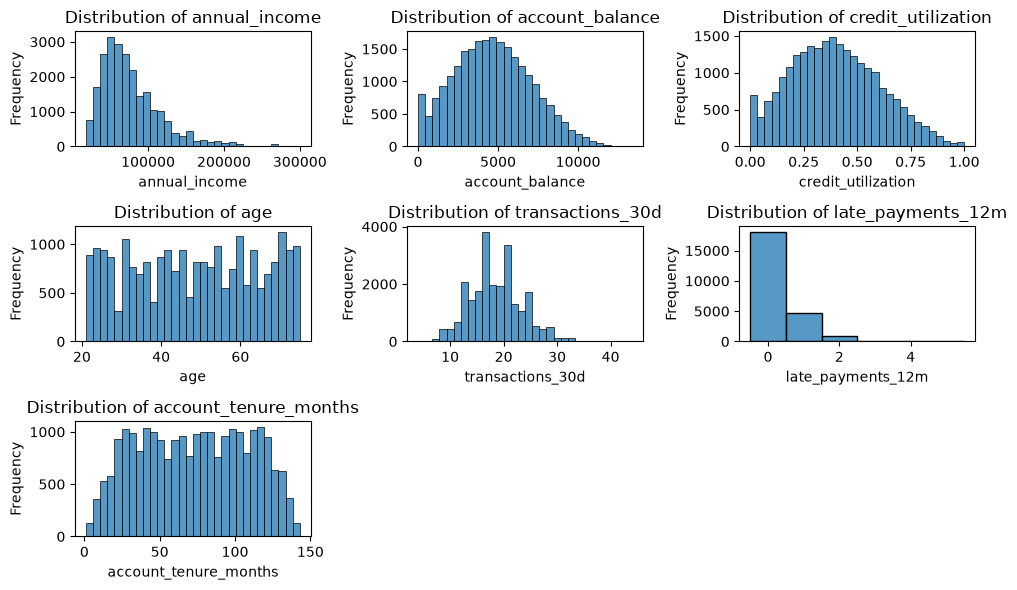

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribution Visualization
# Create the figure once
fig, axes = plt.subplots(
    nrows=3, 
    ncols=3, 
    figsize=(10, 6)
)

# Pair each feature with one subplot
for feature, ax in zip(numerical_features, axes.flat):
    if feature == "late_payments_12m":
        sns.histplot(
            data=df,
            x=feature,
            discrete=True,
            ax=ax
        )
    else:
        sns.histplot(
            data=df,
            x=feature,
            bins=30,
            ax=ax
        )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

# Remove unused axes
for ax in axes.flat[len(numerical_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

1. Late payments are concentrated at zero, with a smaller number of customers having multiple late payments.
2. The distribution of late payments looks approximately right skewed. Late payments are concentrated at zero, with a smaller number of customers having multiple late payments.
3. Most of the customers have an account tenure between around 25 to 125 months. The distribution between those values is approximately uniform.

### 4.6 — Categorical Feature Distributions and Frequency Analysis

We've completed our analysis of the numerical features, including descriptive statistics, skewness, dispersion, and histograms. Now we'll examine the categorical features in our financial dataset:
- `employment_status`
- `region`

Our objective is to understand how customers are distributed across categories, identify underrepresented groups, and determine what these distributions could mean for our eventual machine learning model predicting `missed_payment_60d`. We'll continue using your existing `df` DataFrame.

#### 4.6.1 — Learning Objectives
By the end of this section, you should be able to:
1. Calculate categorical frequencies and relative frequencies using Pandas.
2. Visualize categorical distributions using count plots.
3. Identify rare and underrepresented categories.
4. Distinguish between observation-level and customer-level distributions.
5. Explain how category imbalance can affect model evaluation and generalization.

We will not examine relationships between categorical features and the target yet. That belongs in **Stage 5 — Bivariate and Multivariate EDA**.

#### 4.6.2 — Categorical Frequency Distributions
For numerical features, we used statistics such as the mean, median, standard deviation, and skewness. For categorical features, those statistics generally don't apply. Instead, we examine how frequently each category appears.

**Absolute frequency**

The absolute frequency of category $c$ is:
$$n_c = \sum_{i=1}^{N} 1(X_i = c)$$
Where:
- $N$ is the total number of observations.
- $X_i$ is the categorical value for observation $i$.
- ${1}(X_i=c)$ is 1 when the observation belongs to category $c$, otherwise 0.

**Relative frequency**

The relative frequency measures the proportion of observations belonging to a category:
$$p_c = \frac{n_c}{N}$$
The percentage is:
$$\text{Percentage}_c = \frac{n_c}{N} \times 100$$
For a feature with no missing values:
$$\sum_{c=1}^{K} p_c = 1$$
where $K$ is the number of distinct categories.

For example, suppose a dataset contains 1,000 customers:
| Employment status | Count | Percentage |
| :- | -: | -: |
| Employed | 600 | 60% |
| Self-employed | 200 | 20% |
| Retired | 150 | 15% |
| Unemployed | 50 | 5% |

This tells us that employed customers represent the majority of the population, while unemployed customers represent a relatively small group. However, these frequencies alone tell us nothing about which group is more likely to miss a payment. That requires examining the relationship with the target.

#### 4.6.3 — Task A: Calculate Categorical Frequencies
We'll begin by constructing a frequency table for both categorical features.

**Your task**

Using Pandas, create a summary table containing:
| Column | Meaning |
| :- | :- |
| `feature` | Name of the categorical feature |
| `category` | Individual category |
| `count` | Number of observations |
| `percentage` | Percentage of observations |
| `unique_customers` | Number of distinct customers in that category |

Your output should contain one row per category. For example, `employment_status` has four known categories, so it should contribute four rows.

**Useful Pandas operations**
```
df["employment_status"].value_counts()
```
Returns the frequency of each category.
```
df["employment_status"].value_counts(normalize=True)
```
Returns the proportion of observations belonging to each category.
```
df.groupby("employment_status")["customer_id"].nunique()
```
Returns the number of distinct customers belonging to each employment category.

**Starter code**

Complete the missing portions yourself.
```
categorical_features = [
    "employment_status",
    "region"
]

results = []

for feature in categorical_features:

    # Calculate the absolute frequency
    counts = ...

    # Calculate the relative frequency as a percentage
    percentages = ...

    # Calculate the number of unique customers per category
    unique_customers = ...

    # Combine these results into a summary table
    # Hint: loop through counts.index

categorical_summary = pd.DataFrame(results)

display(categorical_summary)
```
**Important:** Our dataset contains 24 monthly observations per customer. That means an observation-level count is not necessarily the same as a customer-level count.

For example, a customer who remains employed for all 24 months contributes 24 employed observations but only one unique employed customer.

Also, if employment status or region changes across snapshots, the same customer can appear in more than one category's distinct-customer count. We should not assume those categories are constant over time.

In [46]:
# Calculate Categorical Frequencies
categorical_features = [
    "employment_status",
    "region"
]

results = []

for feature in categorical_features:

    counts = df[feature].value_counts()

    percentages = (
        df[feature].value_counts(normalize=True) * 100
    )

    unique_customers = (
        df.groupby(feature)["customer_id"].nunique()
    )

    for category in counts.index:
        results.append({
            "feature": feature,
            "category": category,
            "count": counts[category],
            "percentage": percentages[category],
            "unique_customers": unique_customers[category]
        })

categorical_summary = pd.DataFrame(results)

display(categorical_summary)

,feature,category,count,percentage,unique_customers
0,employment_status,Employed,16800,70.0,700
1,employment_status,Self-employed,3168,13.2,132
2,employment_status,Retired,2208,9.2,92
3,employment_status,Unemployed,1824,7.6,76
4,region,Northeast,6144,25.6,256
5,region,West,6096,25.4,254
6,region,Midwest,6048,25.2,252
7,region,South,5712,23.8,238


#### 4.6.4 — Task B: Visualize Categorical Distributions
Next, create two count plots, one for each categorical feature. A count plot is appropriate because the horizontal axis contains discrete categories rather than continuous numerical values.
```
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 4)
)

for feature, ax in zip(categorical_features, axes):

    sns.countplot(
        data=df,
        x=feature,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Observation Count")

    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()
```
**Questions to answer**

After generating your plots, answer:
1. Which employment category represents the largest share of observations? Which represents the smallest?
2. Is the distribution of customers across regions approximately balanced or heavily concentrated in certain regions?
3. Why might an imbalanced categorical distribution create challenges for model generalization, even when all category values are valid?

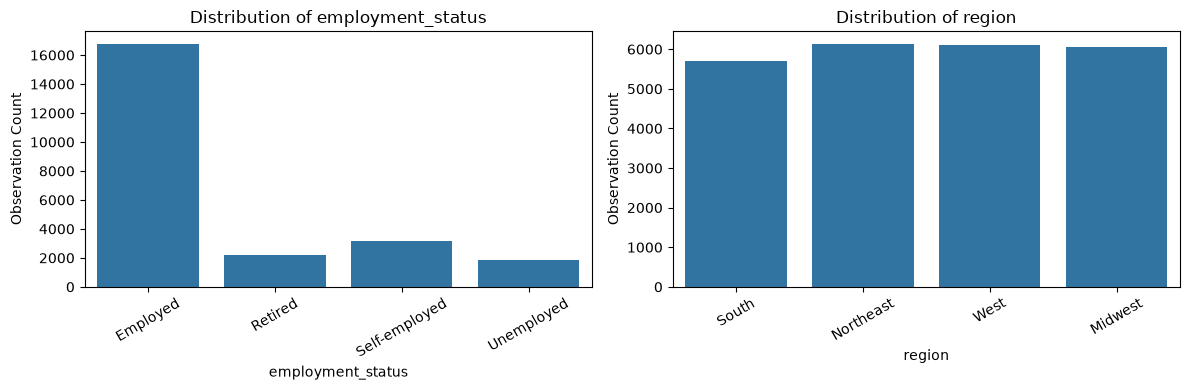

In [47]:
# Visualize Categorical Distributions
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 4)
)

for feature, ax in zip(categorical_features, axes):

    sns.countplot(
        data=df,
        x=feature,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Observation Count")

    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

1. Employed holds the largest share of observations and unemployed hold the smallest share of observations.
2. The distribution of customers across regions is approximately balanced.
3. An imbalanced categorical feature may create challenges for generalization because the model has fewer training examples from underrepresented categories. Consequently, it may learn less reliable predictive relationships for these groups, potentially producing worse performance on those customers even if its overall evaluation metrics appear strong.

#### 4.6.5 — Rare Categories and Representation
One of the most important applications of categorical EDA is identifying rare categories. Suppose a dataset has 100,000 observations, but only 100 belong to a particular employment category. That category represents:
$$p_c = \frac{100}{100000} = 0.001 = 0.1\%$$
A model may have difficulty learning reliable patterns for this group because it has relatively few examples. However, there is a critical distinction: **A rare category is not necessarily an invalid category.** We should not automatically remove or combine categories simply because they have low frequencies. A rare category could represent an important segment of the real population.

**Potential modeling implications**
| Issue | Potential consequence |
| :- | :- |
| Very few observations | Unstable estimates for that category |
| Very few distinct customers | Less independent customer-level information |
| Category absent from training | Model may encounter an unseen category during inference | 
| Category disproportionately represented in one period | Possible temporal distribution shift |
| Category merged into `Other` | Loss of potentially useful information |

For one-hot encoding, `OneHotEncoder(handle_unknown="ignore")` can prevent inference errors from unseen categories, but it does not solve the underlying lack of training examples. Rare-category handling should ultimately be evaluated using the training data and appropriate validation.

#### 4.6.6 — Task C: Identify Underrepresented Categories
For this exercise, we'll define a category as rare when it represents less than 5% of observations. This is an illustrative investigation threshold, not a universal statistical rule. Use your `categorical_summary` DataFrame to identify categories below that threshold.
```
rare_threshold = 5.0

rare_categories = categorical_summary.loc[
    categorical_summary["percentage"] < rare_threshold
]

display(rare_categories)
```
If the output is empty, that simply means none of the categories falls below our chosen threshold. A useful extension is to compare the results with a customer-level percentage, using the number of distinct customers as the denominator. This matters because repeated observations from the same customer are not independent evidence about how well a model will generalize to new customers.

In [48]:
# Identify Underrepresented Categories
rare_threshold = 5.0

rare_categories = categorical_summary.loc[
    categorical_summary["percentage"] < rare_threshold
]

display(rare_categories)

,feature,category,count,percentage,unique_customers


### 4.7 — Target Distribution and Class Balance

We've completed the analysis of our numerical and categorical predictors. Now we need to examine one of the most important variables in our dataset: the target variable. Our machine learning objective is to predict whether a customer will miss a payment within the next 60 days. The target is:
```
missed_payment_60d
```
Where:
- `0` = Customer does not miss a payment within the prediction window.
- `1` = Customer misses a payment within the prediction window.

Before training a classifier, we need to understand how frequently each outcome occurs. This determines the difficulty of our prediction problem, the usefulness of different evaluation metrics, and the baseline performance our model must exceed.

#### 4.7.1 — Learning Objectives
By the end of this section, you should be able to:
1. Calculate the frequency and prevalence of binary target classes.
2. Identify and quantify class imbalance.
3. Calculate majority-class baseline accuracy.
4. Explain why accuracy can be misleading for imbalanced classification.
5. Calculate and interpret precision, recall, and F1-score.
6. Understand the difference between observation-level and customer-level target prevalence.
7. Identify the implications of class imbalance for model training and evaluation.

We'll continue working with the existing 24,000-row financial dataset.

#### 4.7.2 — Understanding Target Class Prevalence
For binary classification, the target variable is:
$$Y_i \in \{0, 1\}$$
The positive-class prevalence is the proportion of observations where $Y=1$:
$$\boxed{\pi = P(Y = 1) \approx \frac{\sum_{i=1}^{N} Y_i}{N}}$$
Where:
- $N$ = Total number of observations.
- $Y_i$ = Binary target for observation $i$.
- $\pi$ = Positive-class prevalence.

Because our target is binary, we can also calculate prevalence using the mean:
$$\bar{Y} = \frac{1}{N} \sum_{i=1}^{N} Y_i$$
Therefore:
$$\boxed{\pi = \bar{Y}}$$
This is an especially useful property of binary variables.

For example, suppose we have 10,000 observations, with 800 missed payments.
$$\pi = \frac{800}{10000} = 0.08$$
Our positive-class prevalence would be 8%. That means 8% of observations correspond to missed payments and 92% correspond to no missed payment.

**Why prevalence matters**

Consider two prediction problems:
| Dataset | No missed payment | Missed payment |
| :- | -: | -: |
| A | 50% | 50% |
| B | 95% | 5% |

In Dataset A, a classifier that always predicts the majority class achieves 50% accuracy. In Dataset B, a classifier that always predicts the majority class achieves 95% accuracy. The same trivial prediction strategy produces dramatically different accuracy scores. This is why model performance must be interpreted relative to the target distribution.

#### 4.7.3 — Task A: Calculate the Target Distribution
Start by calculating the absolute frequency, relative frequency, and positive-class prevalence of `missed_payment_60d`.

**Your task**

Produce a table with the following structure:
| Target | Count | Percentage |
| :- | -: | -: |
| 0 | ... | ... |
| 1 | ... | ... |

Then calculate the positive-class prevalence independently using the mean.

**Starter Code**
```
# Target Distribution
target = "missed_payment_60d"

# Absolute frequency
target_counts = ...

# Relative frequency (%)
target_percentages = ...

# Combine into a summary table
target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percentages
})

display(target_summary)

# Positive-class prevalence
positive_prevalence = ...

print("Positive-class prevalence:", positive_prevalence)
```
**Questions**
1. What percentage of observations belong to the positive class?
2. Is the target approximately balanced or imbalanced?
3. How many negative observations are there for every positive observation?

For Question 3, calculate the imbalance ratio:
$$\boxed{\text{Imbalance Ratio} = \frac{N_0}{N_1}}$$
where $N_0$ and $N_1$ are the negative- and positive-class counts, respectively. For example, a ratio of 9 means there are nine negative observations for every positive observation.

In [49]:
# Calculate the Target Distribution
# Target Distribution
target = "missed_payment_60d"

# Absolute frequency
target_counts = df[target].value_counts()

# Relative frequency (%)
target_percentages = (target_counts / target_counts.sum()) * 100

# Combine into a summary table
target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percentages
})

display(target_summary)

# Positive-class prevalence
positive_prevalence = df[target].mean()

# Imbalance ratio
imbalance_ratio = target_counts[0] / target_counts[1]

print("Positive-class prevalence:", positive_prevalence)
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")


,count,percentage
missed_payment_60d,,
0,22385,93.270833
1,1615,6.729167


Positive-class prevalence: 0.06729166666666667
Imbalance ratio: 13.86:1


1. Approximately 6.73% of observations belong to the positive class.
2. The target is approxmiately imbalanced.
3. $22385/1615 \approx 13.86$. There are approximately 13.86 negative observations for every postive observation.

#### 4.7.4 — Task B: Visualize the Target Distribution
Next, create a count plot showing the frequency of the two classes.
```
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(7, 4))

sns.countplot(
    data=df,
    x="missed_payment_60d",
    order=[0, 1],
    ax=ax
)

ax.set_title("Distribution of Missed Payments")
ax.set_xlabel("Missed Payment Within 60 Days")
ax.set_ylabel("Observation Count")

plt.tight_layout()
plt.show()
```

**Interpretation**

The plot should help us answer:
- Does one class dominate the dataset?
- Is the minority class sufficiently represented to investigate predictive patterns?
- How might the imbalance affect the interpretation of accuracy?

Note that the number of minority-class examples matters in addition to the percentage. A dataset with 5% positive observations and one million records contains far more positive examples than a dataset with 5% positive observations and only 200 records.

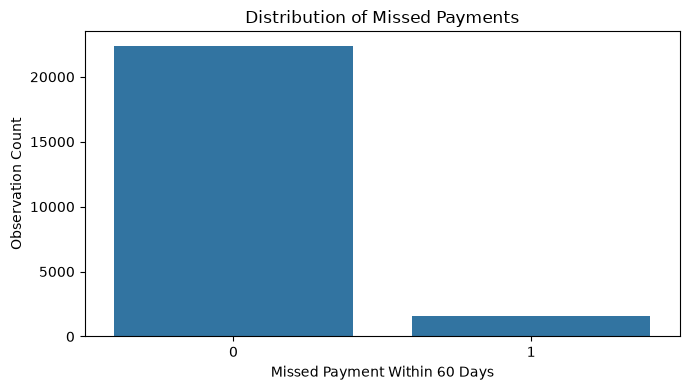

In [50]:
# Visualize the Target Distribution
fig, ax = plt.subplots(figsize=(7, 4))

sns.countplot(
    data=df,
    x="missed_payment_60d",
    order=[0, 1],
    ax=ax
)

ax.set_title("Distribution of Missed Payments")
ax.set_xlabel("Missed Payment Within 60 Days")
ax.set_ylabel("Observation Count")

plt.tight_layout()
plt.show()


#### 4.7.5 — Majority-Class Baseline Accuracy
Before training any machine learning model, we should establish a baseline. The simplest classification baseline predicts the most frequent class for every observation. Suppose:
$$P(Y = 0) = 0.92$$
$$P(Y = 1) = 0.08$$
A classifier that always predicts zero achieves:
$$\text{Accuracy} = 0.92$$
Or 92% accuracy. But it never correctly identifies a missed payment.

**Derivation**

Classification accuracy is:
$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
For a classifier that always predicts the negative class:
$$TP = 0, \qquad FP = 0$$
$$TN = N_0, \qquad FN = N_1$$
Therefore:
$$\text{Accuracy} = \frac{N_0}{N}$$
If the negative class is the majority:
$$\boxed{\text{Baseline Accuracy} = 1 - \pi}$$
More generally, for either majority class:
$$\boxed{\text{Baseline Accuracy} = \max(\pi, 1 - \pi)}$$

**Task C: Calculate Baseline Accuracy**

Without training a model, calculate the accuracy achieved by always predicting the majority class.
```
# Majority-Class Baseline

majority_class = ...

baseline_accuracy = ...

print("Majority class:", majority_class)
print("Baseline accuracy:", baseline_accuracy)
```
**Question:** If our eventual logistic regression model achieves 90% accuracy, would that necessarily be good performance? Explain your answer using the baseline you calculated.

In [51]:
# Calculate Majority-Class Baseline
majority_class = df[target].mode().iloc[0]

baseline_accuracy = df[target].value_counts(normalize=True).max()

print("Majority class:", majority_class)
print(f"Baseline accuracy: {baseline_accuracy:.2%}")

Majority class: 0
Baseline accuracy: 93.27%


A model performing below baseline accuracy is not necessarily worse for the business. We must evaluate the metrics that correspond to the business objective.

#### 4.7.6 — Why Accuracy Can Be Misleading
Consider a hypothetical financial dataset with 1,000 observations:
- 950 customers do not miss a payment.
- 50 customers miss a payment.

Suppose our classifier predicts that no customers will miss a payment. The resulting confusion matrix is:
![](../images/4.7.6-confusion-matrix.png)

The classifier achieves:
$$\text{Accuracy} = \frac{950}{1000} = 95\%$$
Yet it fails to identify every single missed payment. From a business perspective, this could be a completely ineffective model.

**Precision**

Precision measures the proportion of predicted positives that are actually positive.
$$\boxed{\text{Precision} = \frac{TP}{TP + FP}}$$
For our always-negative classifier, precision is undefined because the model makes zero positive predictions. In scikit-learn, it is commonly reported as zero when `zero_division=0` is specified.

**Recall**

Recall measures the proportion of actual positives correctly identified.
$$\boxed{\text{Recall} = \frac{TP}{TP + FN}}$$
For this classifier:
$$\text{Recall} = \frac{0}{0 + 50} = 0$$

**F1-score**

The F1-score is the harmonic mean of precision and recall.
$$\boxed{F_1 = 2 \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}}$$
With no positive predictions and no true positives, the F1-score is conventionally reported as zero.

**Business interpretation**

In our financial application, false negatives and false positives have different potential costs. A false negative means a customer who will miss a payment is not flagged. A false positive means a customer who will not miss a payment is flagged unnecessarily. The preferred balance between precision and recall depends on the intervention, its cost, and the consequences of missing an at-risk customer. We will investigate this more deeply when we begin model evaluation and threshold optimization.

#### 4.7.7 — Observation-Level Versus Customer-Level Prevalence
There's an additional complication in our dataset. We have:
- 1,000 unique customers.
- 24 monthly snapshots per customer.
- 24,000 total observations.

Therefore, our observations are not independent. A customer could have several monthly snapshots labeled `1`, particularly because the target covers a 60-day prediction window and adjacent snapshots can overlap. This means we should distinguish between two different quantities.

**Observation-level prevalence**
$$\pi_{\text{obs}} = \frac{\text{Positive customer-month observations}}{\text{Total customer-month observations}}$$
This tells us how frequently a monthly prediction opportunity has a positive outcome.
**Customer-level ever-positive rate**
$$\pi_{\text{customer}} = \frac{\text{Customers with at least one positive snapshot}}{\text{Total unique customers}}$$
This tells us what fraction of customers experience at least one positive labeled prediction window during the observed period. These quantities are not interchangeable. A customer who has six positive monthly snapshots contributes six positive observations but only one customer to the ever-positive count.

**Task D: Compare the Two Levels**
```
# Observation-level positive prevalence
observation_prevalence = df["missed_payment_60d"].mean()

# Customer-level: did the customer ever have a positive label?
customer_ever_positive = (
    df.groupby("customer_id")["missed_payment_60d"]
    .max()
)

customer_prevalence = customer_ever_positive.mean()

print("Observation-level prevalence:", observation_prevalence)
print("Customer-level ever-positive rate:", customer_prevalence)
```
**Questions**
1. Are the two rates equal?
2. If they differ, what explains the difference?
3. Which quantity would be more relevant if our business objective is to identify customers at risk each month, rather than identifying customers who have ever missed a payment?

For monthly risk scoring, observation-level prevalence is generally the more directly relevant quantity. However, evaluation must still account for repeated customers and overlapping prediction windows.

In [52]:
# Compare the Two Levels
# Observation-level positive prevalence
observation_prevalence = df["missed_payment_60d"].mean()

# Customer-level: did the customer ever have a positive label?
customer_ever_positive = (
    df.groupby("customer_id")["missed_payment_60d"]
    .max()
)

customer_prevalence = customer_ever_positive.mean()

print("Observation-level prevalence:", observation_prevalence)
print("Customer-level ever-positive rate:", customer_prevalence)

Observation-level prevalence: 0.06729166666666667
Customer-level ever-positive rate: 0.544


1. The two rates are not equal
2. A substantial fraction of customers have experienced at least one positive prediction window, even though the positive outcome is relatively uncommon in any particular monthly snapshot.
3. The observation-level prevalence would be more relevant to identify customers at risk each month.

### 4.7.8 — Class Imbalance and Model Training
Once we identify class imbalance, we have several possible modeling approaches. 
| Approach | Purpose | Important consideration |
| :- | :- | :- |
| Class weighting | Increase the contribution of minority-class errors to the training objective | May change probability calibration |
| Oversampling | Increase minority-class representation in training | Must not occur before splitting |
| Undersampling | Reduce majority-class representation | Discards potentially useful observations |
| Threshold adjustment | Change the precision–recall tradeoff | Requires validation data |
| Precision-recall analysis | Evaluate performance on the positive class | Particularly informative for rare positives | 

We should not automatically choose any of these methods based only on prevalence. In particular, do not resample the full dataset before splitting it into training, validation, and test sets. Doing so can introduce leakage and overly optimistic evaluation. Because our data contains repeated customer snapshots, we'll also need to consider whether our evaluation objective concerns future observations of existing customers or completely unseen customers. Those objectives may require different splitting strategies.

### Stage 4.8 — Univariate EDA Summary and Feature-Level Findings
We've completed the individual investigations in Stage 4. Now we need to consolidate our findings into something a data scientist would actually produce before moving into multivariate analysis and model development. This is an important distinction: performing EDA is not the same as documenting the conclusions of EDA. A professional machine learning workflow should produce a record of:
1. What we observed.
2. What those observations mean.
3. Which preprocessing or modeling decisions they suggest.
4. What we still need to investigate.
5. Which decisions should wait until after train/test separation.

For this stage, you'll write the findings yourself. I'll provide the structure, supporting code, and questions, then review your work before we move into Stage 5.

#### 4.8.1 — Our Findings So Far
Based on the results you've shared, here's what we've established.

**Numerical features**
| Feature | Observed characteristics | Potential implication |
| :- | :- | :- |
| `annual_income` | Strong positive skew (1.536); 39 high-income customers flagged by IQR | Investigate extreme values; consider a log transformation |
| `account_balance` | Mild positive skew (0.234) | Standard scaling may be appropriate for scale-sensitive models |
| `credit_utilization` | Mild positive skew (0.253); bounded between 0 and 1 | Preserve valid range; assess relationships with the target |
| `age` | Approximately uniform distribution between 21 and 75 | No obvious distribution-based transformation needed |
| `transactions_30d` | Concentrated around 18 transactions; approximately symmetric | May be suitable without transformation |
| `late_payments_12m` | Strong positive skew (2.163); median and IQR both zero | Treat as a discrete count; investigate zero concentration |
| `account_tenure_months` | Approximately uniform across much of its range; nearly zero skew | No obvious transformation needed |

These are descriptive findings, not final preprocessing decisions. For example, a positively skewed feature does not automatically require a logarithmic transformation. We need to determine whether the transformation improves a particular model's performance.

**Categorical features**
| Feature | Distribution | Interpretation |
| :- | :- | :- |
| `employment_status` | Employed 70%, Self-employed 13.2%, Retired 9.2%, Unemployed 7.6% | Uneven category frequencies |
| `region` | Four regions, approximately 24–26% each | Relatively balanced categories |

No category fell below our 5% rare-category threshold. Remember that categorical imbalance is not necessarily a modeling problem. It becomes more important when a category has too few independent examples to estimate its relationship with the target reliably.

**Target variable**
Missed paymnt within 60 days
| 6.73 % | 93.27% | 54.4% |
| Positive prevalence | Majority baseline accuracy | Customers ever positive |

The target is imbalanced, which suggests that precision, recall, F1, average precision, and business-specific metrics will be more informative than accuracy alone.

#### 4.8.2 — Task A: Build a Reproducible Feature Summary
Instead of manually writing every statistic again, let's build a summary table from the DataFrame. The objective is to combine numerical characteristics with the observations we already identified.

**Your task** 

Create a DataFrame named `feature_summary` with the following columns:
| Column | Purpose |
| :- | :- |
| `feature` | Numerical feature name |
| `mean` | Arithmetic mean |
| `median` | Median |
| `std` | Standard deviation |
| `skewness` | Distribution asymmetry |
| `missing_pct` | Percentage of missing observations |
| `unique_values` | Number of distinct values |
| `zero_pct` | Percentage of observations equal to zero |

You already know how to calculate most of these. Here's the starting structure:
```
# Stage 4.8 — Numerical Feature Summary

results = []

for feature in numerical_features:
    series = df[feature]

    results.append({
        "feature": feature,

        # TODO: Calculate mean
        "mean": ...,

        # TODO: Calculate median
        "median": ...,

        # TODO: Calculate standard deviation
        "std": ...,

        # TODO: Calculate skewness
        "skewness": ...,

        # TODO: Percentage of missing values
        "missing_pct": ...,

        # TODO: Number of unique values
        "unique_values": ...,

        # TODO: Percentage of zero values
        "zero_pct": ...
    })

feature_summary = pd.DataFrame(results)

display(feature_summary)
```
You should be able to complete this without introducing any new libraries.

**Hint:** `isna()`, `nunique()`, `mean()`, and Boolean comparisons are sufficient for the remaining calculations.

**Why calculate zero percentages?**

Consider `late_payments_12m`. Its median and first and third quartiles are all zero. That tells us that at least a large portion of the observations have no recorded late payments, but it doesn't tell us the exact percentage. The zero percentage answers:
$$P(X = 0) = \frac{\text{Number of observations where } X = 0}{N}$$
This is particularly useful for zero-heavy count features.

In [54]:
# Reproducible Numerical Feature Summary
results = []

for feature in numerical_features:
    series = df[feature]

    results.append({
        "feature": feature,
        "mean": series.mean(),
        "median": series.median(),
        "std": series.std(),
        "skewness": series.skew(),
        "missing_pct": series.isna().mean() * 100,
        "unique_values": series.nunique(),
        "zero_pct": (series == 0).mean() * 100
    })

feature_summary = pd.DataFrame(results)

display(feature_summary.round(3))

,feature,mean,median,std,skewness,missing_pct,unique_values,zero_pct
0,annual_income,77204.487,68299.470,40283.675,1.536,0.0,998,0.000
1,account_balance,4688.554,4599.345,2421.885,0.234,0.0,23208,1.854
2,credit_utilization,0.398,0.386,0.208,0.253,0.0,7765,1.717
3,age,48.313,48.500,16.164,-0.026,0.0,55,0.000
4,transactions_30d,18.389,18.000,4.843,0.322,0.0,37,0.000
5,late_payments_12m,0.302,0.000,0.587,2.163,0.0,6,75.396
6,account_tenure_months,72.598,73.000,35.877,-0.015,0.0,143,0.000


#### 4.8.3 — Task B: Create a Feature-Level Decision Log
Next, create a Markdown table in your notebook documenting your proposed treatment of each feature. Use the following structure:
| Feature | Observation | Proposed treatment | Reason |
| :- | :- | :- | :- |
| `annual_income` | Positive skew, high-income outliers | Your decision | Your explanation |
| `account_balance` | Mild skew | Your decision | Your explanation |
| `credit_utilization` | Bounded continuous variable | Your decision | Your explanation |
| `age` | Approximately uniform | Your decision | Your explanation |
| `transactions_30d` | Discrete count | Your decision | Your explanation |
| `late_payments_12m` | Zero-heavy, positive skew | Your decision | Your explanation |
| `account_tenure_months` | Approximately uniform | Your decision | Your explanation |

For each feature, decide whether you would initially recommend:
- No transformation.
- Standard scaling.
- Robust scaling.
- Logarithmic transformation.
- A different transformation or encoding.
- Further investigation before deciding.

You may recommend more than one approach for a feature.

**Important:** These are candidate treatments. We won't fit scalers, imputers, or transformations to the full dataset. Those operations must be learned from the training data after splitting. Also, the appropriate treatment may depend on whether we're using logistic regression, k-nearest neighbors, SVMs, or tree-based models.

| Feature | Observation | Proposed treatment | Reason |
| :- | :- | :- | :- |
| `annual_income` | Positive skew, high-income outliers | Median | annual income is skewed so using the median is a better representation of the average income. |
| `account_balance` | Mild skew | Mean | small skew so using the mean isn't a terrible decision for null values. |
| `credit_utilization` | Bounded continuous variable | Mean | Your explanation |
| `age` | Approximately uniform | Mean | Your explanation |
| `transactions_30d` | Discrete count | Mode | Your explanation |
| `late_payments_12m` | Zero-heavy, positive skew | Leave alone | Your explanation |
| `account_tenure_months` | Approximately uniform | Median | feature is approximately uniform |

#### 4.8.4 — Task C: Identify the Three Most Important Modeling Risks
We have already identified several potential risks:
- Class imbalance.
- Repeated customer observations.
- Overlapping 60-day prediction windows.
- Highly skewed numerical features.
- Extreme income observations.
- Zero-heavy count variables.
- Uneven categorical distributions.
- Possible data-quality inconsistencies.

Your task is to identify the three risks you believe deserve the highest priority before model training.

For each, explain:
1. Why the issue matters.
2. How it could affect model performance or evaluation.
3. What you would do to address or investigate it.
Prioritize based on potential impact, not simply which issues are easiest to fix.

**Risks:**
1. Temporal leakage and repeated customer observations
2. Target imbalance 
3. Data quality and point-in-time feature validity

**Why it matters:**
1. Can invalidate evaluation by exposing future information or allowing inappropriate overlap
2. Only 6.73% of observations are positive; accuracy can be misleading
3. Incorrect, missing, or unavailable-at-prediction-time values can undermine training and deployment

A model trained and evaluated with data leakage can produce impressive validation metrics that are fundamentally unreliable. A model trained on skewed features may still generalize perfectly well, particularly if we use tree-based algorithms. Skewness and outliers remain worth investigating, but they are lower-priority modeling risks.

#### 4.8.5 — Task D: Write Your EDA Conclusion
Finally, write a short professional summary of approximately 150–250 words. Imagine you're presenting your findings to a senior data scientist reviewing the project. Your summary should explain:
- The overall structure of the numerical and categorical features.
- The most important distributional findings.
- The severity and implications of target imbalance.
- What preprocessing approaches you would investigate.
- What must be addressed before reliable model evaluation.

Avoid claiming that a transformation or model will perform better before we've tested it.

Our exploratory analysis identified substantial differences in the distributions of the numerical features. Annual income exhibits positive skewness of approximately 1.54, including 39 customers with values above the IQR upper bound. Historical late payments are even more positively skewed (2.16), with approximately 75.4% of observations reporting zero late payments. Other features, including age and account tenure, exhibit approximately uniform distributions.

The categorical variables show differing levels of representation. Employment status is concentrated among employed customers (70%), whereas regional observations are relatively balanced across four categories.

The target variable, `missed_payment_60d`, is imbalanced, with a positive-class prevalence of 6.73%. A majority-class classifier would achieve approximately 93.27% accuracy without identifying any positive cases. Consequently, accuracy alone will be insufficient for evaluating predictive performance.

Before modeling, we should investigate the validity of extreme income values, evaluate appropriate imputation and transformation strategies, and establish leakage-resistant training and evaluation procedures. Because customers appear repeatedly across monthly observations, chronological separation, overlapping prediction windows, and customer-level dependence require particular attention.

Preprocessing alternatives should be evaluated using training-derived parameters and appropriate validation data rather than selected solely from distributional appearance.